# Cartograma — População + PIB per capita dos municípios baianos
DEC1217 - Visualização Científica (PPGMC/UESC) - Capítulo 7 (Geoespacial) de Schwabish, Better Data Visualizations.

**Pergunta do Notebook:** como a riqueza produzida varia entre os municípios baianos, considerando suas diferenças populacionais?

**Dados:** IBGE – Censo Demográfico 2022 (população) e PIB dos Municípios (PIB a preços correntes). Fonte, licença e data de acesso em data/README.md.




## 1. O que é
Um **cartograma** deforma a geografia para que o *tamanho* de cada unidade represente um dado (aqui, a população), em vez da área territorial. O livro (p. 233–240) descreve quatro famílias:

| Família | Como funciona | Custo |
|---|---|---|
| Contíguo | unidades mudam de tamanho mas continuam encostadas | geografia fica irreconhecível |
| **Não contíguo** | cada unidade encolhe/cresce sobre si mesma e se separa das vizinhas | o espaço vazio passa a ser informação (Judy Olson, 1976) |
| **Gráfico (Dorling)** | cada unidade vira um círculo proporcional ao dado | perde a forma; círculos podem se sobrepor |
| Em grade (tile/hexágono) | uma célula de mesmo tamanho por unidade | perde o tamanho; posições aproximadas |

Implementamos **Dorling** (versão principal) e **não contíguo** (comparação).

## 2. Quando usar
- **Pergunta que responde:** "onde as pessoas estão *e* como esse indicador varia entre elas?"
- **Use quando** a área do território engana: na Bahia, municípios enormes do oeste e do sertão têm pouca gente, e Salvador ocupa um ponto no mapa.
- **Evite quando** o leitor precisa localizar com precisão um município específico, ou quando não há padrão geográfico a mostrar (o livro pergunta: "o mapa é mesmo a melhor visualização?").

## 3. Como ler
1. O **tamanho** do círculo (ou da forma) é a população: quanto maior, mais habitantes.
2. A **cor** é o PIB per capita: cinza = baixo; laranja = alto.
3. A **posição** é aproximada: lembra o mapa da Bahia, mas foi deslocada para os círculos não se sobreporem.
4. Procure **círculos grandes e cinza** (muita gente, pouca riqueza por pessoa) e **círculos pequenos e laranja** (pouca gente, muita riqueza por pessoa).

## 4. Do livro ao nosso dado
### 4.1 Preparação

In [11]:
import re, textwrap, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, LogNorm
import geopandas as gpd
from shapely import affinity


BG, TXT, CINZA, CINZA_ESC, DESTAQUE = '#FFFFFF', '#262626', '#8C8C8C', '#BDBDBD', '#F28C28'
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Calibri', 'Carlito', 'DejaVu Sans'],
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'text.color': TXT, 'axes.labelcolor': TXT, 'xtick.color': CINZA, 'ytick.color': CINZA,
    'axes.edgecolor': CINZA_ESC,
})
CMAP = LinearSegmentedColormap.from_list('cinza_destaque', [CINZA_ESC, DESTAQUE])
FONTE = 'Fonte: IBGE – Censo Demográfico 2022 (população) e PIB dos Municípios (PIB a preços correntes). Elaboração própria.'
Path('figs').mkdir(exist_ok=True)

# ---- Arquivos de entrada  ----
DADOS      = Path('dados')
ARQ_POP    = DADOS / 'tabela_2_1_BA.xlsx'          # SIDRA 4714 – população, Censo 2022
ARQ_PIB    = DADOS / 'tabela5938.csv'              # SIDRA 5938 – PIB dos Municípios
ARQ_MALHA  = DADOS / 'BA_Municipios_2022.shp'      # IBGE > Malhas Territoriais > Municípios 2022 > BA
CRS_METROS = 5880                                  # SIRGAS 2000 / Brasil Policônico (metros)
COR        = 'pib_pc'                              # coluna que pinta os círculos

**Malha municipal:** IBGE → *Geociências → Organização do território → Malhas territoriais → Malhas municipais → 2022 → UFs → BA* (`BA_Municipios_2022.zip`). Descompacte e mantenha `.shp`, `.dbf`, `.shx` e `.prj` juntos em `dados/`.

### 4.2 Leitura e junção das bases

In [12]:
def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    s = re.sub(r'\s*\(ba\)\s*$', '', s)
    s = re.sub(r'[^a-z0-9 ]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

# --- População (Censo 2022) ---
pop = pd.read_excel(ARQ_POP, header=None, skiprows=4, usecols=[0, 1, 2], names=['nome', 'populacao', 'area_km2'])
pop = pop[pop['nome'].astype(str).str.endswith('(BA)')].copy()      # remove linha "Bahia" e rodapé
pop['chave'] = pop['nome'].map(norm)
pop[['populacao', 'area_km2']] = pop[['populacao', 'area_km2']].astype(float)
assert len(pop) == 417

# --- PIB dos Municípios (SIDRA 5938): só usamos PIB total e a participação no PIB da UF ---
pib = pd.read_csv(ARQ_PIB, sep=';', encoding='utf-8-sig', dtype=str, usecols=[0, 1, 2, 5])
pib.columns = ['cod', 'nome', 'pib_mil_reais', 'part_pib_uf']
pib['cod'] = pib['cod'].astype(int)
pib['pib_mil_reais'] = pib['pib_mil_reais'].astype(float)
pib['part_pib_uf'] = pib['part_pib_uf'].str.replace(',', '.').astype(float)
pib['chave'] = pib['nome'].map(norm)
pib = pib.drop(columns='nome')
assert len(pib) == 417

# --- Junção população × PIB (pelo nome normalizado) ---
base = pop.merge(pib, on='chave', how='outer', indicator=True, validate='1:1')
print(base['_merge'].value_counts().to_dict())
assert (base['_merge'] == 'both').all(), base[base['_merge'] != 'both']
base = base.drop(columns='_merge')
base['nome'] = base['nome'].str.replace(r'\s*\(BA\)', '', regex=True)

# --- Indicadores derivados ---
base['pib_pc']   = base['pib_mil_reais'] * 1000 / base['populacao']           # R$ por habitante
base['part_pib'] = 100 * base['pib_mil_reais'] / base['pib_mil_reais'].sum()  # % do PIB da Bahia
base['part_pop'] = 100 * base['populacao'] / base['populacao'].sum()          # % da população da Bahia
base['indice']   = base['part_pib'] / base['part_pop']                        # 1 = proporcional à população

# Verificação: nossa participação recalculada deve bater com a coluna do SIDRA (arredondada em 2 casas)
print('maior diferença vs. SIDRA (p.p.):', round(float((base['part_pib'] - base['part_pib_uf']).abs().max()), 4))
print(f"PIB total BA = R$ {base['pib_mil_reais'].sum()/1e6:,.1f} bi · PIB per capita BA = R$ {base['pib_mil_reais'].sum()*1000/base['populacao'].sum():,.0f}")
base.to_csv('dados_cartograma_bahia.csv', index=False)

{'both': 417, 'left_only': 0, 'right_only': 0}
maior diferença vs. SIDRA (p.p.): 0.005
PIB total BA = R$ 402.6 bi · PIB per capita BA = R$ 28,472


In [13]:
import os
# Se faltar o arquivo .shx, o GDAL o reconstrói automaticamente
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# --- Malha municipal + junção pelo código IBGE ---
malha = gpd.read_file(ARQ_MALHA)
if malha.crs is None:                       # malhas do IBGE estão em SIRGAS 2000 (EPSG:4674)
    malha = malha.set_crs(epsg=4674)
malha = malha.to_crs(CRS_METROS)
print('Colunas da malha:', list(malha.columns))

# Sem o .dbf não há atributos
assert 'CD_MUN' in malha.columns, ('A malha veio sem atributos (.dbf). Baixe o zip completo do IBGE e mantenha '
                                   '.shp, .dbf, .shx e .prj juntos em dados/.')
malha['cod'] = malha['CD_MUN'].astype(int)

gdf = malha[['cod', 'geometry']].merge(base, on='cod', how='outer', indicator=True, validate='1:1')
print(gdf['_merge'].value_counts().to_dict())
assert (gdf['_merge'] == 'both').all(), gdf[gdf['_merge'] != 'both'][['cod', 'nome']]
gdf = gpd.GeoDataFrame(gdf.drop(columns='_merge'), geometry='geometry', crs=CRS_METROS).reset_index(drop=True)

gdf['x'] = gdf.geometry.centroid.x
gdf['y'] = gdf.geometry.centroid.y
assert len(gdf) == 417


Colunas da malha: ['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'AREA_KM2', 'geometry']
{'both': 417, 'left_only': 0, 'right_only': 0}


### 4.3 O que os números dizem

In [14]:
media_ba = base['pib_mil_reais'].sum() * 1000 / base['populacao'].sum()
abaixo = base[base['pib_pc'] < media_ba]
top5 = base.nlargest(5, 'pib_mil_reais')

print(f'PIB per capita: média estadual R$ {media_ba:,.0f} · mediana municipal R$ {base.pib_pc.median():,.0f}')
print(f'{len(abaixo)} municípios ({len(abaixo)/len(base):.0%}) com PIB per capita abaixo da média estadual; '
      f'eles têm {abaixo.part_pop.sum():.0f}% da população')
print(f'5 maiores PIBs ({", ".join(top5.nome)}) = {top5.part_pib.sum():.0f}% do PIB com {top5.part_pop.sum():.0f}% da população')
print('Maiores PIB per capita:'); display(base.nlargest(5, 'pib_pc')[['nome', 'populacao', 'pib_pc']])
print('Menores PIB per capita:'); display(base.nsmallest(5, 'pib_pc')[['nome', 'populacao', 'pib_pc']])

PIB per capita: média estadual R$ 28,472 · mediana municipal R$ 13,362
379 municípios (91%) com PIB per capita abaixo da média estadual; eles têm 80% da população
5 maiores PIBs (Salvador, Camaçari, São Francisco do Conde, Feira de Santana, Luís Eduardo Magalhães) = 39% do PIB com 25% da população
Maiores PIB per capita:


,nome,populacao,pib_pc
356,São Francisco do Conde,38733.0,654785.041179
351,São Desidério,32828.0,289841.659559
134,Formosa do Rio Preto,25899.0,231187.343141
205,Jaborandi,9275.0,179534.016173
110,Correntina,32457.0,126642.388391


Menores PIB per capita:


,nome,populacao,pib_pc
246,Mansidão,13919.0,7633.235146
219,Jussara,16354.0,8170.906200
47,Bom Jesus da Serra,9730.0,8325.899281
228,Lamarão,9015.0,8357.515252
16,Anguera,11031.0,8363.339679


### 4.4 Algoritmo do cartograma de Dorling

Cada município vira um círculo de **área proporcional à população** (raio ∝ √população), começando no centroide. A cada iteração, círculos sobrepostos se afastam (o menor se move mais) e uma mola fraca os puxa de volta à posição geográfica. Nas últimas iterações a mola é desligada para garantir que não sobrem sobreposições.

In [21]:
def dorling(xy, r, n_iter=600, passo=0.6, folga=1.03, mola=0.03, tol=1.0):
    # xy: (n,2) centroides em metros; r: (n,) raios em metros. Retorna posições sem sobreposição.
    rng = np.random.default_rng(0)
    xy0 = xy.astype(float)
    pos = xy0 + rng.normal(0, 1.0, xy0.shape)                 # jitter evita pontos coincidentes
    soma_r = (r[:, None] + r[None, :]) * folga
    peso = r[None, :] / (r[:, None] + r[None, :])              # círculo menor se move mais
    for it in range(n_iter):
        d = pos[:, None, :] - pos[None, :, :]
        dist = np.hypot(d[..., 0], d[..., 1])
        np.fill_diagonal(dist, np.inf)
        sobra = np.clip(soma_r - dist, 0, None)
        if sobra.max() < tol:
            break
        desl = (d / dist[..., None]) * (sobra * peso * passo)[..., None]
        pos = pos + desl.sum(axis=1)
        if it < 0.7 * n_iter:
            pos = pos + mola * (xy0 - pos)
    return pos

### 4.5 Funções de gráfico

In [32]:
def reais(v):
    return f'R$ {v/1000:,.0f} mil'.replace(',', '.')

def media_estado(df):
    return df['pib_mil_reais'].sum() * 1000 / df['populacao'].sum()

def norma(serie, q_min=0.02, q_max=0.98):
    return LogNorm(serie.quantile(q_min), serie.quantile(q_max), clip=True)

def manchete(df):
    media = media_estado(df)
    abaixo = df[df['pib_pc'] < media]
    return (f'{abaixo.populacao.sum()/df.populacao.sum():.0%} dos baianos vivem em municípios '
            f'com PIB per capita abaixo da média do estado ({reais(media)})')

def rotulos_auto(df, col, n_pop=4, n_top=2):
    sel = list(df.nlargest(n_pop, 'populacao')['nome']) + list(df.nlargest(n_top, col)['nome'])
    return list(dict.fromkeys(sel))

def chave_cor(ax, norm_, titulo, ref=None):
    # Chave compacta no canto inferior direito (dentro dos limites do eixo)
    k = ax.inset_axes([0.80, 0.05, 0.38, 0.016]); k.imshow(np.linspace(0, 1, 256)[None, :], aspect='auto', cmap=CMAP)
    k.set_axis_off()
    # Ajustado espaçamento vertical dos limites para baixo (-2.8) para abrir espaço para o rótulo da média
    k.text(0, -2.8, reais(norm_.vmin), transform=k.transAxes, ha='left', va='top', fontsize=9, color=CINZA)
    k.text(1, -2.8, reais(norm_.vmax) + '+', transform=k.transAxes, ha='right', va='top', fontsize=9, color=DESTAQUE)
    k.text(0, 2.2, titulo + ' (escala log.)', transform=k.transAxes, ha='left', va='bottom', fontsize=9, color=TXT)
    if ref is not None:    # marca a média estadual direto na chave
        p = float(norm_(ref))
        k.plot([p, p], [-0.3, 1.3], transform=k.transAxes, color=TXT, lw=1.4, clip_on=False)
        # Texto da média posicionado mais próximo (-0.9) e com quebra de linha para não bater com os outros valores
        k.text(p, -0.9, 'média BA\n' + reais(ref), transform=k.transAxes, ha='center', va='top', fontsize=8, color=TXT, fontweight='bold')

def chave_tamanho(ax, K, x0, y0):
    # Dois círculos de referência lado a lado, alinhados pela base, com rótulo direto abaixo.
    x = x0
    for p in (50_000, 500_000):
        r = K * np.sqrt(p)
        ax.add_patch(Circle((x + r, y0 + r), r, fc='none', ec=CINZA, lw=1))
        ax.annotate(f'{p:,.0f}'.replace(',', '.') + ' hab.', (x + r, y0), xytext=(0, -6), textcoords='offset points',
                    ha='center', va='top', fontsize=9, color=CINZA)
        x += 2 * r + 2.4 * K * np.sqrt(500_000)

def moldura(fig, titulo, subtitulo=None):
    fig.text(0.04, 0.975, textwrap.fill(titulo, 62), ha='left', va='top', fontsize=19, fontweight='bold', color=TXT)
    if subtitulo:
        fig.text(0.04, 0.885, subtitulo, ha='left', va='top', fontsize=11, color=CINZA)
    fig.text(0.04, 0.02, FONTE, ha='left', va='bottom', fontsize=8, color=CINZA)

def mapa_dorling(df, col='pib_pc', rot=None, arquivo=None, alvo_area=0.22):
    df = df.copy()
    K = np.sqrt(alvo_area * df['area_km2'].sum() * 1e6 / np.pi / df['populacao'].sum())   # raio = K*sqrt(pop)
    df['r'] = K * np.sqrt(df['populacao'])
    pos = dorling(df[['x', 'y']].to_numpy(), df['r'].to_numpy())
    df['xd'], df['yd'] = pos[:, 0], pos[:, 1]

    norm_ = norma(df[col])    # log, cortada nos percentis 2 e 98: outliers não 'achatam' o resto
    fig, ax = plt.subplots(figsize=(9, 10.5)); fig.subplots_adjust(top=0.84, bottom=0.06, left=0.02, right=0.98)
    ax.set_aspect('equal'); ax.axis('off')
    patches = [Circle((x, y), r) for x, y, r in zip(df.xd, df.yd, df.r)]
    ax.add_collection(PatchCollection(patches, facecolors=CMAP(norm_(df[col])), edgecolors=BG, linewidths=0.4, alpha=0.92))
    ax.set_xlim(df.xd.min() - df.r.max(), df.xd.max() + df.r.max()); ax.set_ylim(df.yd.min() - df.r.max(), df.yd.max() + df.r.max())

    # Afasta rótulos que se sobrepõem usando as caixas de texto renderizadas.
    textos = []
    pontos = []
    for nome in (rot or rotulos_auto(df, col)):
        l = df[df['nome'] == nome].iloc[0]
        txt = f"{nome}\n{reais(l[col])} → " + f"{l['populacao']:,.0f}".replace(',', '.') + ' hab.'
        ponto = np.array([l.xd, l.yd])
        centro_mapa = df[['xd', 'yd']].to_numpy().mean(axis=0)
        ponto_tela = ax.transData.transform(ponto)
        centro_tela = ax.transData.transform(centro_mapa)
        direcao = ponto_tela - centro_tela
        if np.allclose(direcao, 0):
            direcao = np.array([0.0, 1.0])
        direcao /= np.linalg.norm(direcao)
        rotulo_tela = ponto_tela + direcao * 80
        rotulo_dados = ax.transData.inverted().transform(rotulo_tela)
        textos.append(ax.text(*rotulo_dados, txt, fontsize=9.5, color=TXT,
                              ha='center', va='center', zorder=5))
        pontos.append(tuple(ponto))

    for _ in range(120):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        caixas = [t.get_window_extent(renderer).expanded(1.06, 1.12) for t in textos]
        movimentos = [np.zeros(2) for _ in textos]
        colisao = False
        for i in range(len(caixas)):
            for j in range(i + 1, len(caixas)):
                if caixas[i].overlaps(caixas[j]):
                    colisao = True
                    ci = np.array(caixas[i].get_points()).mean(axis=0)
                    cj = np.array(caixas[j].get_points()).mean(axis=0)
                    direcao = ci - cj
                    if np.allclose(direcao, 0):
                        direcao = np.array([(-1) ** i, (-1) ** j], dtype=float)
                    direcao /= np.linalg.norm(direcao)
                    movimentos[i] += direcao * 2.5
                    movimentos[j] -= direcao * 2.5
        if not colisao:
            break
        for texto, delta in zip(textos, movimentos):
            if np.any(delta):
                pos_tela = ax.transData.transform(texto.get_position()) + delta
                texto.set_position(ax.transData.inverted().transform(pos_tela))

    # Desenha uma linha-guia de cada rótulo até o círculo correspondente.
    fig.canvas.draw()
    for texto, (x, y) in zip(textos, pontos):
        centro = np.array(texto.get_window_extent(fig.canvas.get_renderer()).get_points()).mean(axis=0)
        destino = ax.transData.inverted().transform(centro)
        ax.annotate('', xy=(x, y), xytext=destino, textcoords='data',
                    arrowprops=dict(arrowstyle='-', color=CINZA, lw=0.8), zorder=4)
    chave_cor(ax, norm_, 'PIB per capita', ref=media_estado(df))
    xmin, ymin = ax.get_xlim()[0], ax.get_ylim()[0]
    chave_tamanho(ax, K, xmin + 0.3*K*np.sqrt(500_000), ymin + 0.9*K*np.sqrt(500_000))
    moldura(fig, manchete(df), 'Cada círculo é um município; a área é proporcional à população (Censo 2022).')
    if arquivo: fig.savefig(arquivo, dpi=200)
    return fig, df

### 4.6 Dorling (população + PIB per capita)

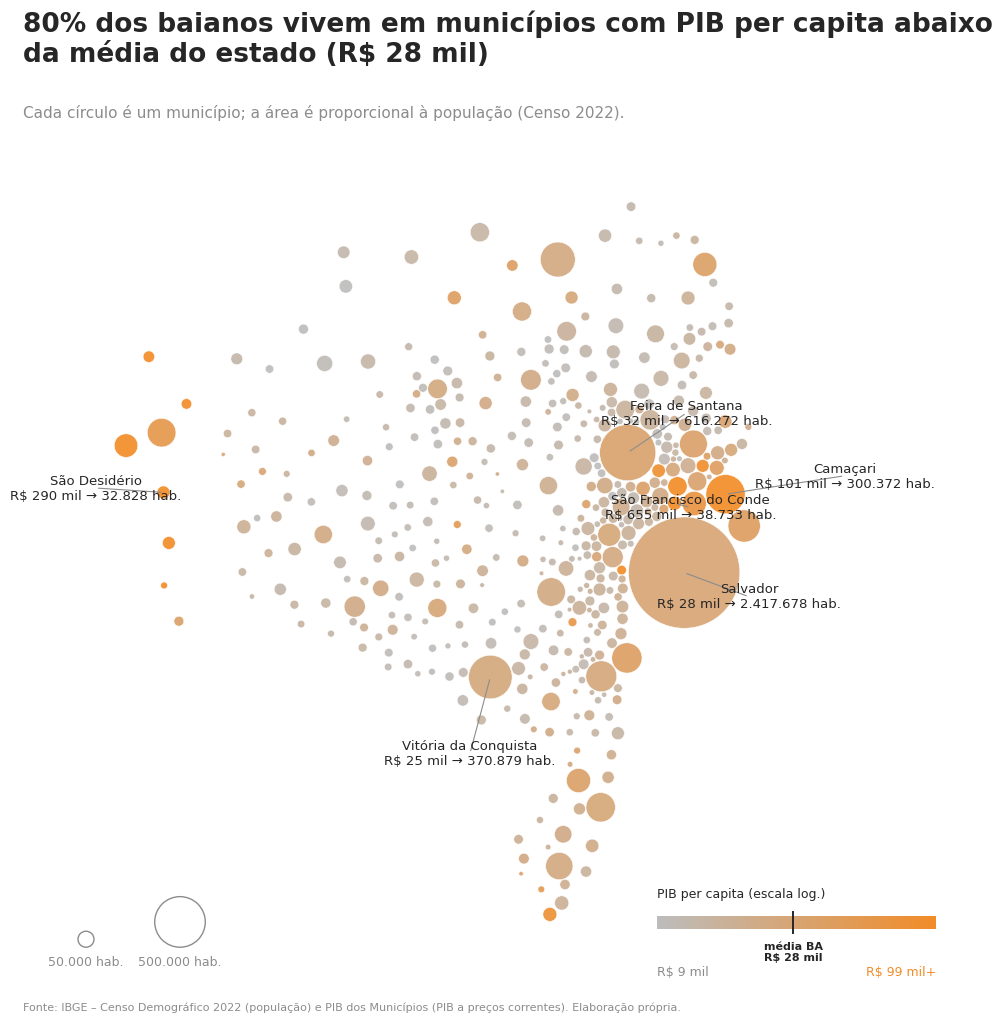

In [33]:
fig, dor = mapa_dorling(gdf, COR, arquivo='figs/cartograma_dorling_pib_pc.png')
plt.show()

### 4.7 Versão não contígua (forma preservada, tamanho = população)

Cada município **encolhe sobre o próprio centroide** por √(densidade / densidade-âncora), como na proposta de Olson: o espaço vazio entre as formas mostra o quanto a densidade é menor. Como a Bahia tem densidades muito díspares, a âncora é o percentil `ancora_q`; municípios acima dela ficam em tamanho real (limitação a ser dita na apresentação).

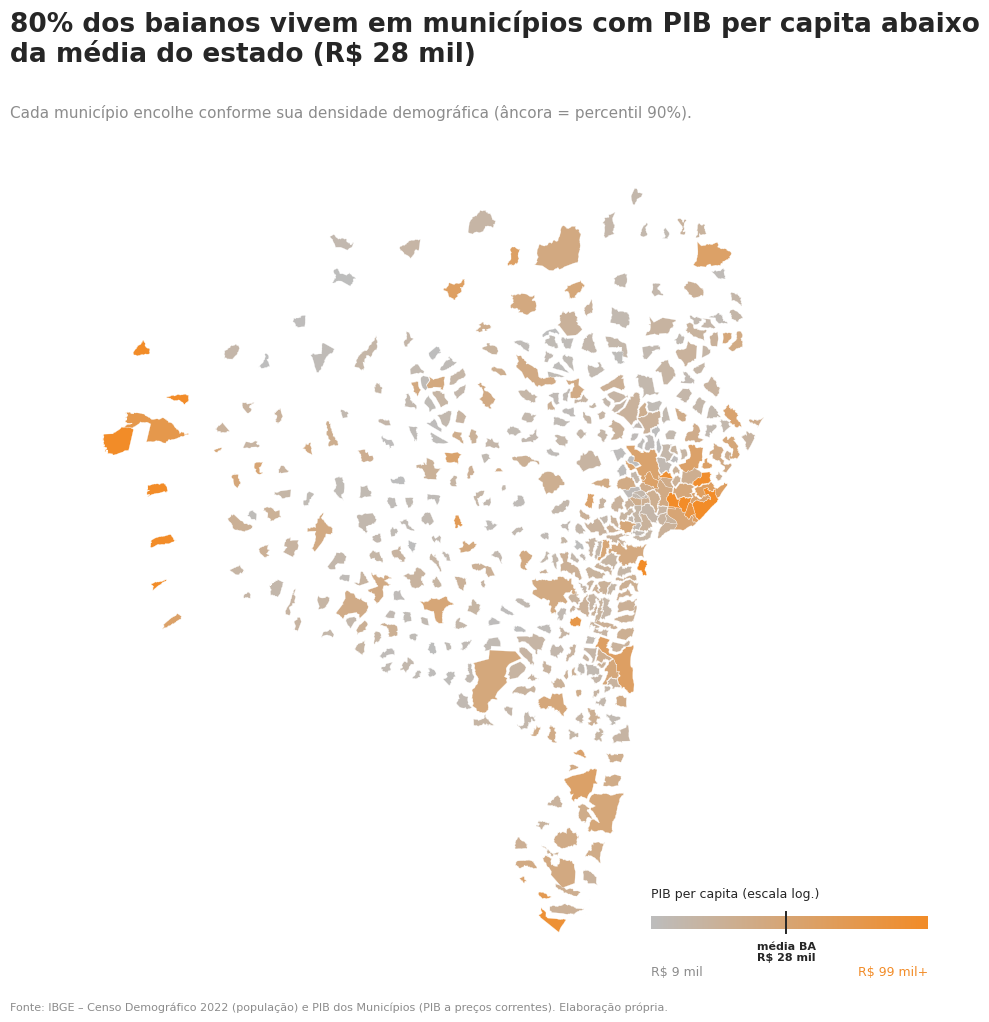

In [34]:
def nao_contiguo(g, col='pib_pc', ancora_q=0.90, arquivo=None):
    g = g.copy()
    dens = g['populacao'] / (g.geometry.area / 1e6)
    fator = np.sqrt((dens / dens.quantile(ancora_q)).clip(upper=1))
    g['geometry'] = [affinity.scale(geom, xfact=f, yfact=f, origin='centroid') for geom, f in zip(g.geometry, fator)]
    norm_ = norma(g[col])
    fig, ax = plt.subplots(figsize=(9, 10.5)); fig.subplots_adjust(top=0.84, bottom=0.06, left=0.04, right=0.98)
    ax.set_aspect('equal'); ax.axis('off')
    g.plot(ax=ax, color=CMAP(norm_(g[col])), edgecolor=BG, linewidth=0.2)
    chave_cor(ax, norm_, 'PIB per capita', ref=media_estado(g))
    moldura(fig, manchete(g), f'Cada município encolhe conforme sua densidade demográfica (âncora = percentil {ancora_q:.0%}).')
    if arquivo: fig.savefig(arquivo, dpi=200)
    return fig


fig = nao_contiguo(gdf, COR, arquivo='figs/cartograma_nao_contiguo_pib_pc.png')
plt.show()


## 5. Boas práticas
**Erros comuns em cartogramas** (e como evitamos):
1. **Escala por raio em vez de área** — o círculo parece quadraticamente maior. Aqui raio ∝ √população.
2. **Círculos que se escondem** — contorno na cor do fundo e leve transparência.
3. **Paleta arco-íris** e legenda distante — cinza → **uma** cor de destaque, com chave de cor rotulada nas pontas.
4. **Rotular tudo** — rotulamos só os 4 maiores e os 2 de maior PIB per capita.
5. **Título descritivo** ("Cartograma da Bahia") — o título é uma manchete que diz a conclusão.
6. **Valores extremos** estragando a escala — escala logarítmica cortada nos percentis 2 e 98, declarada na chave, com a média estadual marcada.

### 5.1 Redesenho: antes e depois

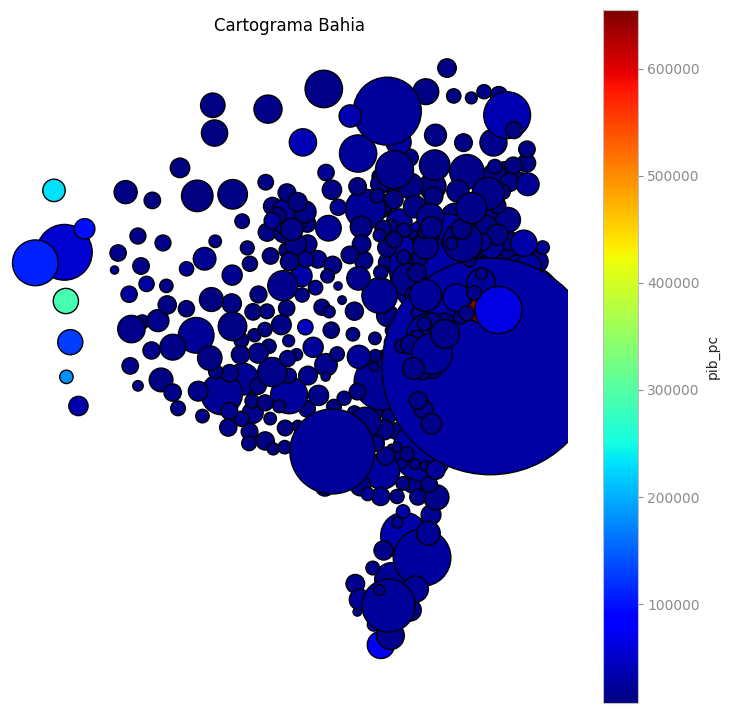

In [19]:
def antes_dorling(df, col='pib_pc'):
    df = df.copy()
    K = np.sqrt(0.22 * df['area_km2'].sum() * 1e6 / np.pi / df['populacao'].sum())
    df['r'] = K * np.sqrt(df['populacao'])
    pos = dorling(df[['x', 'y']].to_numpy(), df['r'].to_numpy())
    with mpl.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black'}):
        fig, ax = plt.subplots(figsize=(9, 9), facecolor='white'); ax.set_aspect('equal')
        sc = ax.scatter(pos[:, 0], pos[:, 1], s=(2 * df['r'] / 1000) ** 2 * 0.9, c=df[col], cmap='jet',
                        edgecolors='black', linewidths=1)
        fig.colorbar(sc, ax=ax, label=col); ax.set_title('Cartograma Bahia'); ax.axis('off')
        fig.savefig('figs/cartograma_ANTES.png', dpi=150, facecolor='white')
    return fig

antes_dorling(gdf); plt.show()

## 6. Alternativas
| Alternativa | Responde bem | Custo |
|---|---|---|
| **Mapa coroplético** | "onde fica?" — formato familiar | municípios enormes e vazios dominam o olhar (distorção geográfica) |
| **Gráfico de bolhas** (população × PIB per capita) | relação entre tamanho e riqueza por habitante, sem distorção | perde a geografia: o leitor não "se acha" no mapa |
| **Mapa em grade (tile/hexágono)** | comparar unidades de mesmo peso | com 417 municípios fica inviável; melhor para territórios de identidade |
| **Cartograma de Dorling (esta técnica)** | população e cor ao mesmo tempo | geografia aproximada; círculos pequenos difíceis de achar |

A alternativa sem mapa que mais responde à pergunta:

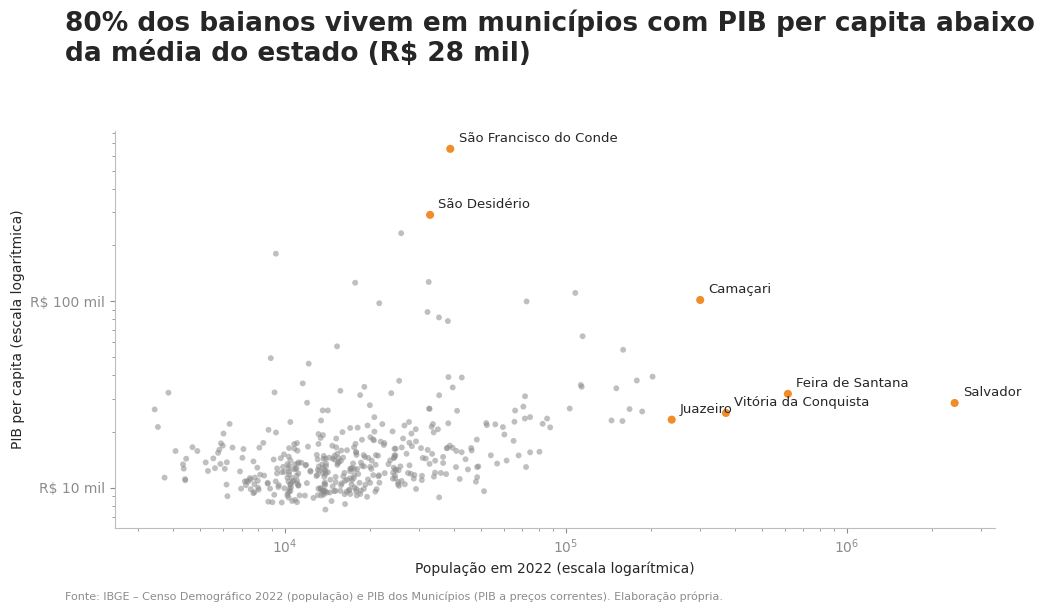

In [20]:
def bolhas(df, col='pib_pc', arquivo=None):
    fig, ax = plt.subplots(figsize=(10, 6.2)); fig.subplots_adjust(top=0.78, bottom=0.14, left=0.09, right=0.97)
    ax.scatter(df['populacao'], df[col], s=18, color=CINZA, alpha=0.55, edgecolors='none')
    dest = pd.concat([df.nlargest(5, 'populacao'), df.nlargest(2, col)]).drop_duplicates('nome')
    ax.scatter(dest['populacao'], dest[col], s=34, color=DESTAQUE, edgecolors='none')
    for _, l in dest.iterrows():
        ax.annotate(l['nome'], (l['populacao'], l[col]), xytext=(6, 5), textcoords='offset points', fontsize=9.5, color=TXT)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: reais(v)))
    ax.set_xlabel('População em 2022 (escala logarítmica)'); ax.set_ylabel('PIB per capita (escala logarítmica)')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    moldura(fig, manchete(df))
    if arquivo: fig.savefig(arquivo, dpi=200)
    return fig

bolhas(gdf, COR, arquivo='figs/alternativa_bolhas_pib_pc.png'); plt.show()

## 7. O que levar deste notebook e referências
- O mapa comum mostra **território**; o cartograma mostra **pessoas**. Para a pergunta da pesquisa, pessoas são o que importa.
- Todo cartograma troca **fidelidade geográfica** por **fidelidade ao dado**; diga isso ao público.
- Mesmo bem feito, é menos familiar que o mapa comum; combine com um gráfico (as bolhas acima) quando o leitor precisar de valores exatos.

**Referências**
- Schwabish, J. *Better Data Visualizations: A Guide for Scholars, Researchers, and Wonks*. Columbia University Press, 2021. Cap. 7 (p. 233–240, cartogramas).
- IBGE. *Censo Demográfico 2022* — SIDRA, Tabela 4714 (população e área).
- IBGE. *PIB dos Municípios* — SIDRA, Tabela 5938.
- IBGE. *Malhas Territoriais — Municípios 2022*.
- Olson, J. (1976). Noncontiguous area cartograms. *The Professional Geographer*, 28(4). · Dorling, D. (1996). *Area Cartograms*. CATMOG 59.